In [7]:
import os
import json
import random
import shutil
from datetime import datetime
from pathlib import Path
from typing import Optional, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from IPython.display import display

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.metrics import accuracy_score, f1_score

import joblib

# -----------------------
# Dataset path (ONLY this)
# -----------------------
DATASET_PATH = r"csv_data"  # <-- CHANGE ONLY THIS

# -----------------------
# Run folder (main folder)
# -----------------------
BASE_OUT_DIR = Path("v5")  # <-- main folder
RUN_NAME = "v1"
DATASET_NAME = "ISCX_VPN_NONVPN_STATS_LEVEL"

# -----------------------
# Data settings
# -----------------------
DATA_PATH = DATASET_PATH
LABEL_COL: Optional[str] = None  # auto-infer if None
GROUP_COL: Optional[str] = None  # auto-infer if None (by hints)
DROP_COLS: Optional[List[str]] = None  # optional manual extra drop cols

TEST_SIZE = 0.2
VAL_SIZE = 0.1
SEED = 42

# -----------------------
# Training settings
# -----------------------
BATCH_SIZE = 256
EPOCHS = 35
LR = 1e-3
WEIGHT_DECAY = 1e-4
EARLY_STOP_PATIENCE = 8

# -----------------------
# Preprocess settings
# -----------------------
CORR_THRESHOLD = 0.975
VT_THRESHOLD = 1e-5
SKEW_RATIO_THRESH = 1e3

# -----------------------
# Imbalance control
# -----------------------
AUTO_SMOTE = True
SMOTE_K_NEIGHBORS = 5

# -----------------------
# Model defaults
# -----------------------
MODEL_DROP = 0.35
FOCAL_GAMMA = 1.5
LR_FACTOR = 0.5
LR_PATIENCE = 3

# -----------------------
# Unknown router
# -----------------------
DBSCAN_EPS = 0.7
DBSCAN_MIN_SAMPLES = 20

# -----------------------
# Device + seeds
# -----------------------
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------
# Paths (single source)
# -----------------------
RUN_DIR = BASE_OUT_DIR / RUN_NAME
paths = {
    "root": RUN_DIR,
    "cache": RUN_DIR / "cache",
    "logs": RUN_DIR / "logs",
    "preprocess": RUN_DIR / "preprocess",
    "models": RUN_DIR / "models",
    "plots": RUN_DIR / "plots",
}
for p in paths.values():
    if isinstance(p, Path):
        p.mkdir(parents=True, exist_ok=True)


# -----------------------
# Simple direct save helpers
# -----------------------
def save_json(path: Path, obj) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def save_fig(path: Path, dpi: int = 200) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=dpi)

In [8]:
config = {
    "DATA_PATH": DATA_PATH,
    "DATASET_NAME": DATASET_NAME,
    "RUN_NAME": RUN_NAME,
    "LABEL_COL": LABEL_COL,
    "GROUP_COL": GROUP_COL,
    "DROP_COLS": DROP_COLS,
    "TEST_SIZE": TEST_SIZE,
    "VAL_SIZE": VAL_SIZE,
    "SEED": SEED,
    "BATCH_SIZE": BATCH_SIZE,
    "EPOCHS": EPOCHS,
    "LR": LR,
    "WEIGHT_DECAY": WEIGHT_DECAY,
    "EARLY_STOP_PATIENCE": EARLY_STOP_PATIENCE,
    "CORR_THRESHOLD": CORR_THRESHOLD,
    "VT_THRESHOLD": VT_THRESHOLD,
    "SKEW_RATIO_THRESH": SKEW_RATIO_THRESH,
    "AUTO_SMOTE": AUTO_SMOTE,
    "SMOTE_K_NEIGHBORS": SMOTE_K_NEIGHBORS,
    "MODEL_DROP": MODEL_DROP,
    "FOCAL_GAMMA": FOCAL_GAMMA,
    "LR_FACTOR": LR_FACTOR,
    "LR_PATIENCE": LR_PATIENCE,
    "DBSCAN_EPS": DBSCAN_EPS,
    "DBSCAN_MIN_SAMPLES": DBSCAN_MIN_SAMPLES,
}
save_json(paths["logs"] / "config.json", config)

print("DEVICE:", DEVICE)
print("Artifacts root:", paths["root"])

# ======================
# 1) Load CSV/ARFF folder
# ======================
EXCLUDE_DEFAULT = {"source_file"}

PREF_EXACT = ["class", "label", "traffic", "traffic_type", "family", "category", "app", "application"]
PREF_SUB = ["class", "label", "traffic", "family", "category", "app", "type"]
GROUP_HINTS = ["flow_id", "flowid", "session_id", "session", "fid", "connection_id", "conn_id"]


def _decode_bytes(df: pd.DataFrame) -> pd.DataFrame:
    for c in df.columns:
        if pd.api.types.is_object_dtype(df[c]):
            df[c] = df[c].map(lambda x: x.decode("utf-8", "ignore") if isinstance(x, (bytes, bytearray)) else x)
    return df


def _coerce_numeric_objects(df: pd.DataFrame, min_fraction: float = 0.85) -> pd.DataFrame:
    for c in df.columns:
        if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):
            s = df[c].astype(str)
            converted = pd.to_numeric(s, errors="coerce")
            if converted.notna().mean() >= min_fraction:
                df[c] = converted
    return df


def read_arff_file(fp: Path) -> pd.DataFrame:
    try:
        from scipy.io import arff as scipy_arff
        data, _ = scipy_arff.loadarff(str(fp))
        df = pd.DataFrame(data)
        return _decode_bytes(df)
    except Exception:
        import arff as liac_arff
        with open(fp, "r", encoding="utf-8", errors="ignore") as f:
            obj = liac_arff.load(f)
        cols = [a[0] for a in obj["attributes"]]
        df = pd.DataFrame(obj["data"], columns=cols)
        return _decode_bytes(df)


def read_csv_file(fp: Path) -> pd.DataFrame:
    return pd.read_csv(fp)


def load_dataset(path: str) -> pd.DataFrame:
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(path)

    def load_one(fp: Path) -> Optional[pd.DataFrame]:
        if fp.suffix.lower() == ".csv":
            df = read_csv_file(fp)
        elif fp.suffix.lower() == ".arff":
            df = read_arff_file(fp)
        else:
            return None
        df = _decode_bytes(df)
        df["source_file"] = fp.name
        return df

    if p.is_dir():
        files = sorted([*p.glob("*.csv"), *p.glob("*.arff")])
        if not files:
            raise ValueError(f"No CSV/ARFF files found in folder: {path}")
        frames = [load_one(fp) for fp in files]
        frames = [f for f in frames if f is not None]
        cols = sorted(set().union(*[set(f.columns) for f in frames]))
        frames = [f.reindex(columns=cols) for f in frames]
        df = pd.concat(frames, ignore_index=True)
        return df

    if p.suffix.lower() == ".csv":
        df = read_csv_file(p)
    elif p.suffix.lower() == ".arff":
        df = read_arff_file(p)
    else:
        raise ValueError("Unsupported file type. Use CSV/ARFF or a folder.")

    df = _decode_bytes(df)
    if "source_file" not in df.columns:
        df["source_file"] = p.name
    return df


raw = load_dataset(DATA_PATH)
raw = _coerce_numeric_objects(raw)
print("Raw shape:", raw.shape)
display(raw.head(3))

DEVICE: cuda
Artifacts root: v5\v1
Raw shape: (59707, 27)


,class1,duration,flowBytesPerSecond,flowPktsPerSecond,max_active,max_biat,max_fiat,max_flowiat,max_idle,mean_active,...,min_flowiat,min_idle,source_file,std_active,std_biat,std_fiat,std_flowiat,std_idle,total_biat,total_fiat
0,CHAT,117202678.0,1411.640099,3.916293,35334176.0,5.578672e+05,474297.570850,35137650.0,35137650.0,5.561680e+06,...,4.0,1079974.0,TimeBasedFeatures-Dataset-120s-AllinOne.csv,7.589073e+06,NaN,NaN,1.839548e+06,7.605741e+06,4.0,17.0
1,CHAT,119579137.0,1731.104649,3.821737,35280803.0,5.410036e+05,510804.294872,35022877.0,35022877.0,4.972742e+06,...,4.0,1065834.0,TimeBasedFeatures-Dataset-120s-AllinOne.csv,7.131588e+06,NaN,NaN,1.849452e+06,7.108954e+06,4.0,16.0
2,CHAT,90462788.0,701.404427,1.912389,24613894.0,1.145099e+06,981250.445652,24244301.0,24244301.0,9.991859e+06,...,5.0,1297996.0,TimeBasedFeatures-Dataset-120s-AllinOne.csv,8.779228e+06,NaN,NaN,2.842532e+06,9.259661e+06,5.0,20.0


In [9]:
def choose_label_col(df: pd.DataFrame, exclude: Optional[set] = None) -> str:
    exclude = set(exclude or set())
    exclude = exclude.union(EXCLUDE_DEFAULT).union(set(DROP_COLS or []))

    cols = [c for c in df.columns if c not in exclude]

    def score_col(c: str) -> Tuple[int, float]:
        name = c.lower()
        exact = 2 if name in PREF_EXACT else 0
        sub = 1 if any(s in name for s in PREF_SUB) else 0
        nunq = df[c].dropna().astype(str).nunique()
        miss = float(df[c].isna().mean())
        cardinality_penalty = abs(nunq - 10)
        return (exact + sub, -(cardinality_penalty + 10 * miss))

    cands = []
    for c in cols:
        nunq = df[c].dropna().astype(str).nunique()
        if 2 <= nunq <= max(50, int(0.2 * len(df))):
            cands.append((score_col(c), c))

    if not cands:
        raise ValueError("Could not infer label column. Set LABEL_COL manually.")
    cands.sort(reverse=True)
    return cands[0][1]


label_col = LABEL_COL or choose_label_col(raw)
print("Chosen label_col:", label_col)
print(raw[label_col].astype(str).value_counts().head(15))

group_col = GROUP_COL
if group_col is None:
    for c in raw.columns:
        if c.lower() in GROUP_HINTS:
            group_col = c
            break
print("Auto group_col:", group_col)


Chosen label_col: class1
class1
BROWSING     20000
VOIP         12061
FT            8679
P2P           7415
CHAT          5344
MAIL          3808
STREAMING     2399
Name: count, dtype: int64
Auto group_col: None


Dropped all-NaN columns: 0
Rows after dedup: 46176
X shape: (46176, 25) n_classes: 8


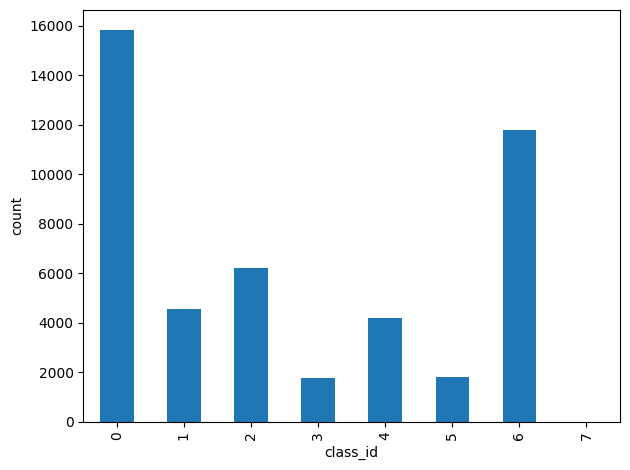

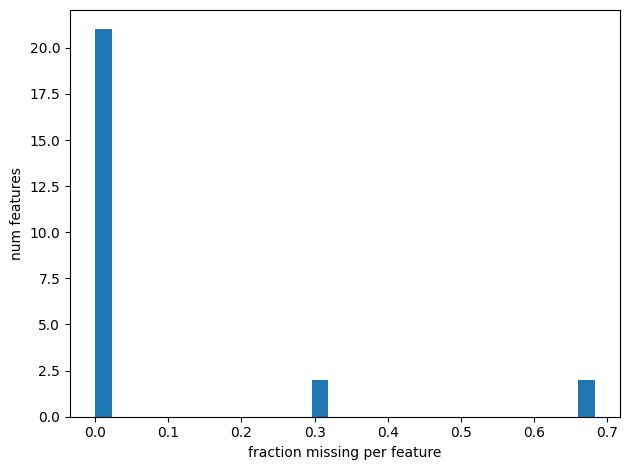

std_biat              0.683169
std_fiat              0.683169
total_fiat            0.316853
total_biat            0.316853
max_biat              0.000022
flowBytesPerSecond    0.000022
flowPktsPerSecond     0.000022
max_active            0.000022
duration              0.000022
mean_active           0.000022
dtype: float64

In [10]:
default_drop = {"source_file"}
DROP_COLS = DROP_COLS or []
drop_cols = set(DROP_COLS).union(default_drop)

y_raw = raw[label_col].astype(str)
X_df = raw.drop(columns=[label_col], errors="ignore").copy()
X_df = X_df.drop(columns=[c for c in drop_cols if c in X_df.columns], errors="ignore")

for c in X_df.columns:
    if pd.api.types.is_object_dtype(X_df[c]) or pd.api.types.is_string_dtype(X_df[c]):
        X_df[c] = pd.to_numeric(X_df[c], errors="coerce")
X_df = X_df.replace([np.inf, -np.inf], np.nan)

all_nan_cols = [c for c in X_df.columns if X_df[c].isna().all()]
if all_nan_cols:
    X_df = X_df.drop(columns=all_nan_cols)
print("Dropped all-NaN columns:", len(all_nan_cols))

dup_mask = X_df.duplicated(keep="first")
if dup_mask.any():
    X_df = X_df.loc[~dup_mask].copy()
    y_raw = y_raw.loc[X_df.index]
print("Rows after dedup:", len(X_df))

le = LabelEncoder()
y_all = le.fit_transform(y_raw.values)
classes = list(le.classes_)
save_json(paths["logs"] / "classes.json", {"classes": classes})

print("X shape:", X_df.shape, "n_classes:", len(classes))

miss = X_df.isna().mean().sort_values(ascending=False)

plt.figure()
pd.Series(y_all).value_counts().sort_index().plot(kind="bar")
plt.xlabel("class_id")
plt.ylabel("count")
save_fig(paths["plots"] / "class_distribution.png")
plt.show()

plt.figure()
plt.hist(miss.values, bins=30)
plt.xlabel("fraction missing per feature")
plt.ylabel("num features")
save_fig(paths["plots"] / "missingness_hist.png")
plt.show()

display(miss.head(10))

In [11]:
def _min_count_for_stratified(test_size: float, val_size: float) -> int:
    val_ratio = val_size / max(1e-9, (1.0 - test_size))
    for n in range(2, 200):
        n_test = max(1, int(np.ceil(test_size * n)))
        n_trainval = n - n_test
        if n_trainval < 2:
            continue
        n_val = max(1, int(np.ceil(val_ratio * n_trainval)))
        n_train = n_trainval - n_val
        if n_train >= 1 and n_val >= 1:
            return n
    return 3


min_count = _min_count_for_stratified(TEST_SIZE, VAL_SIZE)
label_counts = pd.Series(y_raw.values).value_counts()
rare_labels = label_counts[label_counts < min_count].index.tolist()

save_json(
    paths["logs"] / "label_counts_raw.json",
    {
        "min_required": int(min_count),
        "counts": label_counts.to_dict(),
        "rare_labels": rare_labels,
    },
)

counts = pd.Series(y_all).value_counts()
rare_class_ids = counts[counts < 2].index.tolist()

if rare_class_ids:
    print("Rare class ids (encoded) -> holding out as unknown:", rare_class_ids)

    rare_mask = np.isin(y_all, rare_class_ids)

    # Save rare samples for traceability (optional but recommended)
    rare_dump = raw.loc[X_df.index].copy()
    rare_dump["_label_raw"] = y_raw.values
    rare_dump["_label_enc"] = y_all
    rare_dump["_is_rare"] = rare_mask
    rare_dump.loc[rare_mask].to_csv(paths["logs"] / "rare_unknown_holdout.csv", index=False)

    # Filter out rare samples from training pool
    X_df = X_df.loc[~rare_mask].copy()
    y_raw = y_raw.loc[X_df.index].copy()

    # Re-encode after filtering (important!)
    le = LabelEncoder()
    y_all = le.fit_transform(y_raw.values)
    classes = list(le.classes_)
    save_json(paths["logs"] / "classes.json", {"classes": classes, "dropped_rare_encoded_ids": rare_class_ids})

    print("After filtering ->", X_df.shape, "min class count =", pd.Series(y_all).value_counts().min())
else:
    print("All classes have >=2 samples. Stratified split is safe.")


Rare class ids (encoded) -> holding out as unknown: [7]
After filtering -> (46175, 25) min class count = 1774


In [12]:
def split_indices(y: np.ndarray, groups: Optional[np.ndarray], test_size: float, val_size: float, seed: int):
    idx = np.arange(len(y))

    if groups is not None:
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        train_val_idx, test_idx = next(gss.split(idx, y, groups))
        g_train_val = groups[train_val_idx]

        val_ratio = val_size / (1.0 - test_size)
        gss2 = GroupShuffleSplit(n_splits=1, test_size=val_ratio, random_state=seed)
        tr_rel, va_rel = next(gss2.split(train_val_idx, y[train_val_idx], g_train_val))
        train_idx = train_val_idx[tr_rel]
        val_idx = train_val_idx[va_rel]
        return train_idx, val_idx, test_idx

    train_val_idx, test_idx = train_test_split(idx, test_size=test_size, random_state=seed, stratify=y)
    val_ratio = val_size / (1.0 - test_size)
    train_idx, val_idx = train_test_split(train_val_idx, test_size=val_ratio, random_state=seed,
                                          stratify=y[train_val_idx])
    return train_idx, val_idx, test_idx


groups = raw.loc[X_df.index, group_col].astype(str).values if group_col and group_col in raw.columns else None

tr_idx, va_idx, te_idx = split_indices(y_all, groups, TEST_SIZE, VAL_SIZE, SEED)
np.save(paths["cache"] / "idx_train.npy", tr_idx)
np.save(paths["cache"] / "idx_val.npy", va_idx)
np.save(paths["cache"] / "idx_test.npy", te_idx)

X_train_raw = X_df.iloc[tr_idx].copy()
X_val_raw = X_df.iloc[va_idx].copy()
X_test_raw = X_df.iloc[te_idx].copy()

y_train = y_all[tr_idx]
y_val = y_all[va_idx]
y_test = y_all[te_idx]

print("Split sizes:", len(X_train_raw), len(X_val_raw), len(X_test_raw))


Split sizes: 32322 4618 9235


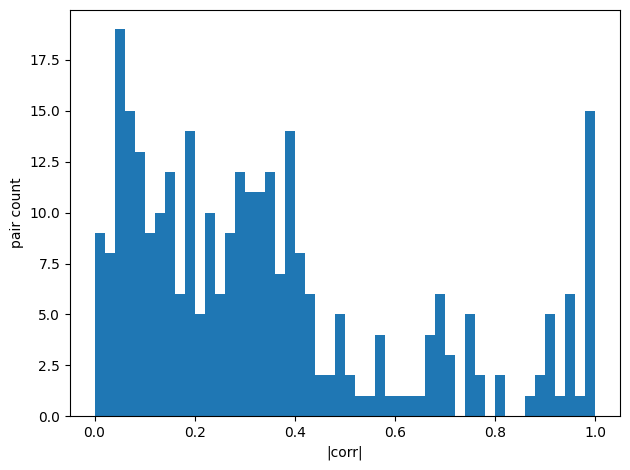

Final features: 18


In [13]:
def fit_shiftlog(X_train: pd.DataFrame, skew_ratio_thresh: float):
    mins = np.nanmin(X_train.values, axis=0)
    shift = np.where(mins < 0, -mins, 0.0)

    Xs = X_train.values + shift
    med = np.nanmedian(Xs, axis=0)
    mx = np.nanmax(Xs, axis=0)
    ratio = mx / (med + 1.0)

    log_mask = (ratio > skew_ratio_thresh).astype(bool)
    return {"shift": shift, "log_mask": log_mask, "cols": X_train.columns.tolist(),
            "skew_ratio_thresh": float(skew_ratio_thresh)}


def apply_shiftlog(X: pd.DataFrame, params: dict) -> pd.DataFrame:
    cols = params["cols"]
    X = X.reindex(columns=cols)
    arr = X.values.astype(float) + np.array(params["shift"], dtype=float)
    mask = np.array(params["log_mask"], dtype=bool)
    if mask.any():
        arr[:, mask] = np.maximum(arr[:, mask], -0.999999)
        arr[:, mask] = np.log1p(arr[:, mask])
    out = pd.DataFrame(arr, columns=cols, index=X.index)
    return out.replace([np.inf, -np.inf], np.nan)


raw_cols = X_train_raw.columns.tolist()
save_json(paths["logs"] / "train_feature_cols.json", {"train_feature_cols": raw_cols})

X_val_raw = X_val_raw.reindex(columns=raw_cols)
X_test_raw = X_test_raw.reindex(columns=raw_cols)

shiftlog_params = fit_shiftlog(X_train_raw, SKEW_RATIO_THRESH)
joblib.dump(shiftlog_params, paths["preprocess"] / "shiftlog_params.joblib")

X_train_sl = apply_shiftlog(X_train_raw, shiftlog_params)
X_val_sl = apply_shiftlog(X_val_raw, shiftlog_params)
X_test_sl = apply_shiftlog(X_test_raw, shiftlog_params)

imp = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imp.fit_transform(X_train_sl), columns=raw_cols, index=X_train_sl.index)
X_val_imp = pd.DataFrame(imp.transform(X_val_sl), columns=raw_cols, index=X_val_sl.index)
X_test_imp = pd.DataFrame(imp.transform(X_test_sl), columns=raw_cols, index=X_test_sl.index)
joblib.dump(imp, paths["preprocess"] / "imputer_median.joblib")

vt = VarianceThreshold(threshold=VT_THRESHOLD)
X_train_vt_np = vt.fit_transform(X_train_imp.values)
kept_vt = [raw_cols[i] for i in vt.get_support(indices=True)]
X_train_vt = pd.DataFrame(X_train_vt_np, columns=kept_vt, index=X_train_imp.index)
X_val_vt = X_val_imp[kept_vt].copy()
X_test_vt = X_test_imp[kept_vt].copy()

joblib.dump(vt, paths["preprocess"] / "variance_threshold.joblib")
save_json(paths["logs"] / "kept_after_vt.json", {"kept_features": kept_vt})

corr_df = X_train_vt
if len(corr_df) > 50000:
    corr_df = corr_df.sample(50000, random_state=SEED)

corr = corr_df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().reset_index().rename(columns={"level_0": "A", "level_1": "B", 0: "abs_corr"}).sort_values(
    "abs_corr", ascending=False)
high = pairs[pairs["abs_corr"] > CORR_THRESHOLD].reset_index(drop=True)
to_drop = sorted(set(high["B"].tolist()))

X_train_corr = X_train_vt.drop(columns=to_drop, errors="ignore")
X_val_corr = X_val_vt.drop(columns=to_drop, errors="ignore")
X_test_corr = X_test_vt.drop(columns=to_drop, errors="ignore")
kept_features = X_train_corr.columns.tolist()

high.to_csv(paths["logs"] / "high_corr_pairs_train.csv", index=False)
save_json(paths["logs"] / "corr_dropped.json", {"threshold": CORR_THRESHOLD, "dropped": to_drop})
save_json(paths["logs"] / "kept_features.json", {"kept_features": kept_features})

plt.figure()
plt.hist(upper.stack().dropna().values, bins=50)
plt.xlabel("|corr|")
plt.ylabel("pair count")
save_fig(paths["plots"] / "corr_hist.png")
plt.show()

robust = RobustScaler()
std = StandardScaler()

X_train_scaled = std.fit_transform(robust.fit_transform(X_train_corr.values))
X_val_scaled = std.transform(robust.transform(X_val_corr.values))
X_test_scaled = std.transform(robust.transform(X_test_corr.values))

X_train = pd.DataFrame(X_train_scaled, columns=kept_features, index=X_train_corr.index)
X_val = pd.DataFrame(X_val_scaled, columns=kept_features, index=X_val_corr.index)
X_test = pd.DataFrame(X_test_scaled, columns=kept_features, index=X_test_corr.index)

joblib.dump(robust, paths["preprocess"] / "robust_scaler.joblib")
joblib.dump(std, paths["preprocess"] / "standard_scaler.joblib")

print("Final features:", len(kept_features))

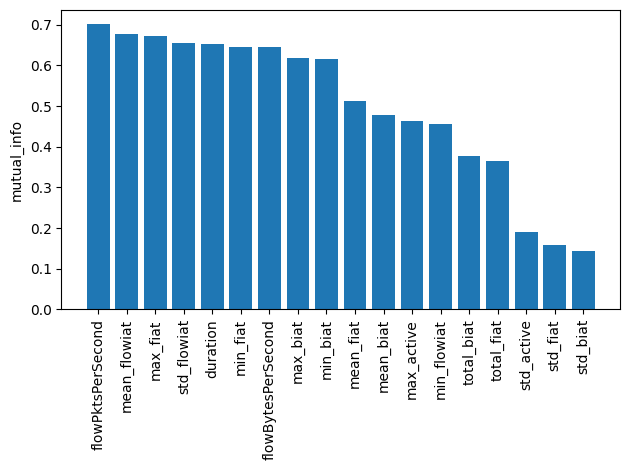

Train class counts: Counter({np.int64(0): 11087, np.int64(6): 8252, np.int64(2): 4342, np.int64(1): 3198, np.int64(4): 2936, np.int64(5): 1265, np.int64(3): 1242})
Imbalance ratio: 8.926731078904991
SMOTE available: True -> using SMOTE: True
After SMOTE: Counter({np.int64(0): 11087, np.int64(6): 11087, np.int64(5): 11087, np.int64(1): 11087, np.int64(4): 11087, np.int64(2): 11087, np.int64(3): 11087})


In [14]:
try:
    mi = mutual_info_classif(X_train.values, y_train, random_state=SEED)
    mi_df = pd.DataFrame({"feature": kept_features, "mutual_info": mi}).sort_values("mutual_info", ascending=False)
    mi_df.to_csv(paths["logs"] / "feature_rank_mutual_info.csv", index=False)

    plt.figure()
    top = mi_df.head(30)
    plt.bar(range(len(top)), top["mutual_info"].values)
    plt.xticks(range(len(top)), top["feature"].values, rotation=90)
    plt.ylabel("mutual_info")
    save_fig(paths["plots"] / "mutual_info_top30.png")
    plt.show()
except Exception as e:
    print("Mutual information ranking skipped:", e)

# ================================
# 8) SMOTE (optional, train only)
# ================================
from collections import Counter

IMBLEARN_OK = True
try:
    from imblearn.over_sampling import SMOTE
except Exception:
    IMBLEARN_OK = False

train_counts = Counter(y_train)
imb_ratio = (max(train_counts.values()) / max(1, min(train_counts.values())))
use_smote = bool(AUTO_SMOTE and IMBLEARN_OK and imb_ratio >= 1.5)

print("Train class counts:", train_counts)
print("Imbalance ratio:", float(imb_ratio))
print("SMOTE available:", IMBLEARN_OK, "-> using SMOTE:", use_smote)

X_train_bal = X_train.copy()
y_train_bal = y_train.copy()

if use_smote:
    k = min(SMOTE_K_NEIGHBORS, max(1, min(train_counts.values()) - 1))
    sm = SMOTE(random_state=SEED, k_neighbors=k)
    X_res, y_res = sm.fit_resample(X_train.values, y_train)
    X_train_bal = pd.DataFrame(X_res, columns=kept_features)
    y_train_bal = y_res
    print("After SMOTE:", Counter(y_train_bal))

Epoch 001 | train_loss=0.6628 | train_acc=0.6417 | val_acc=0.6971 | val_macro_f1=0.6431 | test_acc=0.7040
Epoch 002 | train_loss=0.4146 | train_acc=0.7627 | val_acc=0.7159 | val_macro_f1=0.6731 | test_acc=0.7267
Epoch 003 | train_loss=0.3657 | train_acc=0.7898 | val_acc=0.7828 | val_macro_f1=0.7221 | test_acc=0.7842
Epoch 004 | train_loss=0.3281 | train_acc=0.8059 | val_acc=0.8110 | val_macro_f1=0.7584 | test_acc=0.8125
Epoch 005 | train_loss=0.3010 | train_acc=0.8198 | val_acc=0.8120 | val_macro_f1=0.7623 | test_acc=0.8112
Epoch 006 | train_loss=0.2895 | train_acc=0.8239 | val_acc=0.8166 | val_macro_f1=0.7666 | test_acc=0.8220
Epoch 007 | train_loss=0.2759 | train_acc=0.8320 | val_acc=0.8049 | val_macro_f1=0.7621 | test_acc=0.8036
Epoch 008 | train_loss=0.2661 | train_acc=0.8367 | val_acc=0.8246 | val_macro_f1=0.7829 | test_acc=0.8254
Epoch 009 | train_loss=0.2545 | train_acc=0.8400 | val_acc=0.8138 | val_macro_f1=0.7668 | test_acc=0.8108
Epoch 010 | train_loss=0.2506 | train_acc=0.84

,epoch,train_loss,train_acc,val_acc,val_macro_f1,test_acc,test_macro_f1
25,26,0.155263,0.892732,0.862711,0.828097,0.864537,0.829436
26,27,0.154661,0.892860,0.865959,0.830765,0.862588,0.826268
27,28,0.152274,0.894007,0.869424,0.835727,0.863996,0.830879
28,29,0.151012,0.894819,0.864227,0.827785,0.862913,0.827724
29,30,0.150683,0.894394,0.861845,0.827296,0.862371,0.827605
30,31,0.148452,0.896004,0.864877,0.830172,0.862371,0.829477
31,32,0.148844,0.897151,0.873538,0.839834,0.869843,0.839299
32,33,0.145961,0.898401,0.864660,0.830365,0.867244,0.832134
33,34,0.145743,0.898710,0.868774,0.832780,0.865295,0.828119
34,35,0.146715,0.898659,0.862711,0.828027,0.862480,0.829161


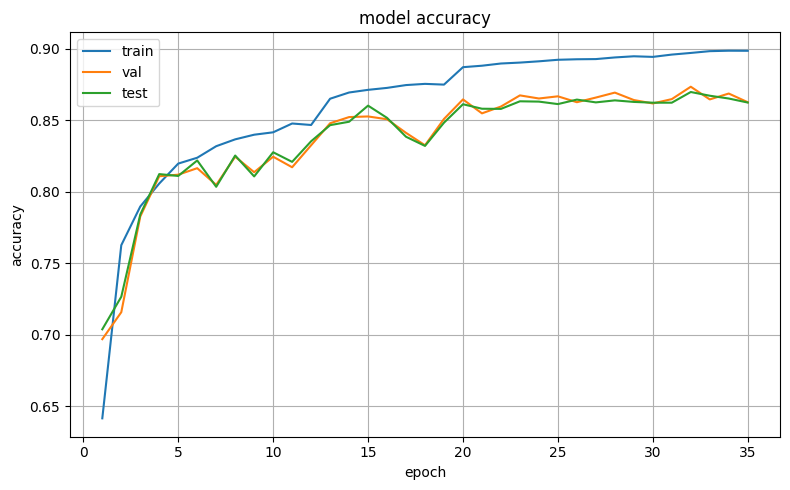

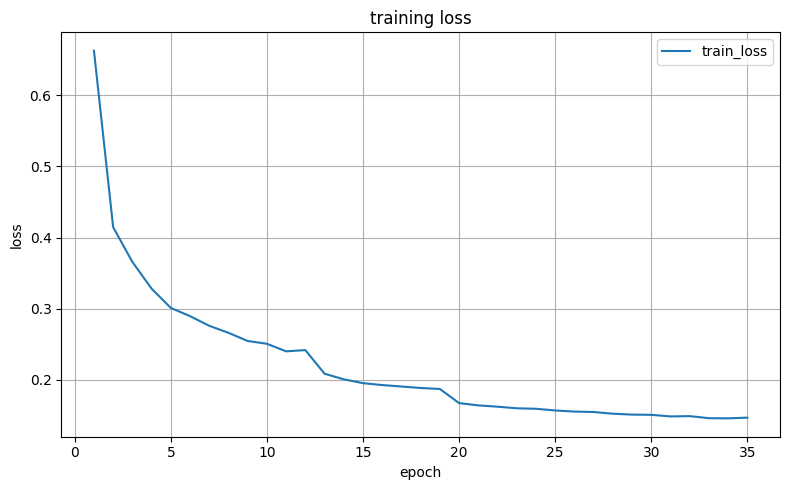

In [15]:
class Tabular1DDataset(Dataset):
    def __init__(self, X: pd.DataFrame, y: np.ndarray | None = None):
        self.X = torch.from_numpy(np.asarray(X, dtype=np.float32))
        self.y = None if y is None else torch.from_numpy(np.asarray(y, dtype=np.int64))

    def __len__(self) -> int:
        return int(self.X.shape[0])

    def __getitem__(self, i: int):
        xi = self.X[i].unsqueeze(0)  # (1,F)
        return (xi, self.y[i]) if self.y is not None else xi


class FeatureCNN_Attn(nn.Module):
    def __init__(self, n_classes: int, drop: float = 0.35):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 128, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(128, 256, 3, padding=1)
        self.bn2 = nn.BatchNorm1d(256)

        self.attn = nn.MultiheadAttention(embed_dim=256, num_heads=4, dropout=drop, batch_first=True)
        self.ln = nn.LayerNorm(256)

        self.emb_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(drop),
        )
        self.out = nn.Linear(128, n_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))  # (B,256,F)
        x = x.transpose(1, 2)  # (B,F,256)

        attn_out, _ = self.attn(x, x, x)
        x = self.ln(x + attn_out)
        x = x.mean(dim=1)  # (B,256)

        emb = self.emb_head(x)  # (B,128)
        logits = self.out(emb)  # (B,C)
        return logits, emb


class FocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor | None = None, gamma: float = 1.5):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce = F.cross_entropy(logits, targets, reduction="none", weight=self.alpha)
        with torch.no_grad():
            pt = torch.softmax(logits, dim=1).gather(1, targets.view(-1, 1)).squeeze(1).clamp_min(1e-9)
        loss = ((1.0 - pt) ** self.gamma) * ce
        return loss.mean()


counts = np.bincount(y_train_bal, minlength=len(classes)).astype(np.float32)
w = (1.0 / np.maximum(counts, 1.0))
w = w / w.mean()
class_weights_t = torch.tensor(w, dtype=torch.float32, device=DEVICE)
save_json(paths["logs"] / "class_weights.json", {"class_weights": w.tolist()})

train_loader = DataLoader(Tabular1DDataset(X_train_bal, y_train_bal), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0)
val_loader = DataLoader(Tabular1DDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(Tabular1DDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = FeatureCNN_Attn(n_classes=len(classes), drop=MODEL_DROP).to(DEVICE)
criterion = FocalLoss(alpha=class_weights_t, gamma=FOCAL_GAMMA)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=LR_FACTOR, patience=LR_PATIENCE)

best_val_f1 = -1.0
bad_epochs = 0
best_path = paths["models"] / "cnn_best.pt"

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_macro_f1": [],
    "test_acc": [],
    "test_macro_f1": [],
}


def eval_loader(model: nn.Module, loader: DataLoader):
    model.eval()
    all_preds, all_true, all_logits, all_emb = [], [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            logits, emb = model(xb)
            preds = logits.argmax(dim=1)

            all_preds.append(preds.detach().cpu().numpy())
            all_true.append(yb.detach().cpu().numpy())
            all_logits.append(logits.detach().cpu().numpy())
            all_emb.append(emb.detach().cpu().numpy())

    y_true = np.concatenate(all_true) if len(all_true) else np.array([], dtype=np.int64)
    y_pred = np.concatenate(all_preds) if len(all_preds) else np.array([], dtype=np.int64)
    logits = np.concatenate(all_logits, axis=0) if len(all_logits) else np.zeros((0, len(classes)), dtype=np.float32)
    emb = np.concatenate(all_emb, axis=0) if len(all_emb) else np.zeros((0, 128), dtype=np.float32)

    macro_f1 = float(f1_score(y_true, y_pred, average="macro")) if len(y_true) else float("nan")
    acc = float((y_true == y_pred).mean()) if len(y_true) else float("nan")

    return {"macro_f1": macro_f1, "acc": acc}, y_true, y_pred, logits, emb


for epoch in range(1, int(EPOCHS) + 1):
    model.train()
    running = 0.0
    n = 0
    correct = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits, _ = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += float(loss.item()) * xb.size(0)
        n += xb.size(0)
        correct += int((logits.argmax(dim=1) == yb).sum().item())

    train_loss = running / max(n, 1)
    train_acc = correct / max(n, 1)

    val_metrics, _, _, _, _ = eval_loader(model, val_loader)
    test_metrics, _, _, _, _ = eval_loader(model, test_loader)

    val_f1 = val_metrics["macro_f1"]
    if not np.isnan(val_f1):
        scheduler.step(val_f1)

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_metrics["acc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["test_acc"].append(test_metrics["acc"])
    history["test_macro_f1"].append(test_metrics["macro_f1"])

    if (not np.isnan(val_f1)) and (val_f1 > best_val_f1):
        best_val_f1 = val_f1
        bad_epochs = 0
        torch.save({"state_dict": model.state_dict(), "best_val_f1": best_val_f1, "epoch": epoch}, best_path)
    else:
        bad_epochs += 1

    print(
        f"Epoch {epoch:03d} | train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"val_acc={val_metrics['acc']:.4f} | val_macro_f1={val_metrics['macro_f1']:.4f} | "
        f"test_acc={test_metrics['acc']:.4f}"
    )

    if bad_epochs >= int(EARLY_STOP_PATIENCE):
        print("Early stopping.")
        break

ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])
print("Loaded best:", str(best_path), "best_val_f1:", ckpt.get("best_val_f1"), "epoch:", ckpt.get("epoch"))

hist_df = pd.DataFrame(history)
hist_df.to_csv(paths["logs"] / "training_history.csv", index=False)
hist_df.to_json(paths["logs"] / "training_history.json", orient="records", indent=2)
display(hist_df.tail(10))

# ==========================
# 10) Training curves (saved)
# ==========================
hist_path = paths["logs"] / "training_history.csv"
hist = pd.read_csv(hist_path)

plt.figure(figsize=(8, 5))
plt.plot(hist["epoch"], hist["train_acc"], label="train")
plt.plot(hist["epoch"], hist["val_acc"], label="val")
plt.plot(hist["epoch"], hist["test_acc"], label="test")
plt.title("model accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(paths["logs"] / "model_accuracy_curve.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(hist["epoch"], hist["train_loss"], label="train_loss")
plt.title("training loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(paths["logs"] / "train_loss_curve.png", dpi=200)
plt.show()

In [16]:
def softmax_np(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(z)
    return exp / exp.sum(axis=1, keepdims=True)


@torch.no_grad()
def collect_logits_emb(model: nn.Module, loader: DataLoader):
    model.eval()
    L, Y, E = [], [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        logits, emb = model(xb)
        L.append(logits.detach().cpu().numpy())
        E.append(emb.detach().cpu().numpy())
        Y.append(yb.detach().cpu().numpy())
    return np.concatenate(L, axis=0), np.concatenate(Y, axis=0), np.concatenate(E, axis=0)


def ece_score(probs: np.ndarray, y_true: np.ndarray, bins: int = 15) -> float:
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for i in range(bins):
        lo, hi = edges[i], edges[i + 1]
        m = (conf >= lo) & (conf < hi)
        if m.sum() == 0:
            continue
        ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def nll_score(probs: np.ndarray, y_true: np.ndarray) -> float:
    p = np.clip(probs[np.arange(len(y_true)), y_true], 1e-12, 1.0)
    return float(-np.mean(np.log(p)))


def brier_score(probs: np.ndarray, y_true: np.ndarray, n_classes: int) -> float:
    y_onehot = np.zeros((len(y_true), n_classes), dtype=np.float32)
    y_onehot[np.arange(len(y_true)), y_true] = 1.0
    return float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))


def reliability_curve_data(probs: np.ndarray, y_true: np.ndarray, bins: int = 15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    centers = (edges[:-1] + edges[1:]) / 2.0

    accs, confs, counts = [], [], []
    for i in range(bins):
        lo, hi = edges[i], edges[i + 1]
        m = (conf >= lo) & (conf < hi)
        if m.sum() == 0:
            accs.append(np.nan);
            confs.append(np.nan);
            counts.append(0)
        else:
            accs.append(float(correct[m].mean()))
            confs.append(float(conf[m].mean()))
            counts.append(int(m.sum()))
    return centers, np.array(accs), np.array(confs), np.array(counts)


def plot_reliability(probs: np.ndarray, y_true: np.ndarray, title: str, bins: int = 15):
    centers, accs, _, _ = reliability_curve_data(probs, y_true, bins=bins)
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1])
    plt.plot(centers, accs, marker="o")
    plt.xlabel("confidence")
    plt.ylabel("accuracy")
    plt.title(title)
    plt.grid(True)


In [17]:
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(1))

    def forward(self, logits: torch.Tensor) -> torch.Tensor:
        t = torch.exp(self.log_t).clamp(1e-3, 1e3)
        return logits / t

    def temperature(self) -> float:
        return float(torch.exp(self.log_t).detach().cpu().item())

    def fit(self, logits: np.ndarray, y_true: np.ndarray, max_iter: int = 50) -> float:
        self.to(DEVICE)
        x = torch.tensor(logits, dtype=torch.float32, device=DEVICE)
        y = torch.tensor(y_true, dtype=torch.long, device=DEVICE)
        opt = torch.optim.LBFGS([self.log_t], lr=0.1, max_iter=max_iter)

        def closure():
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(self.forward(x), y)
            loss.backward()
            return loss

        opt.step(closure)
        return self.temperature()


def routing_sweep(probs: np.ndarray, y_true: np.ndarray, thresholds: Optional[np.ndarray] = None) -> pd.DataFrame:
    if thresholds is None:
        thresholds = np.linspace(0.0, 1.0, 101)
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    rows = []
    for t in thresholds:
        accept = conf >= t
        coverage = float(accept.mean())
        if accept.sum() == 0:
            rows.append({"threshold": float(t), "coverage": coverage, "macro_f1": float("nan")})
        else:
            rows.append({
                "threshold": float(t),
                "coverage": coverage,
                "macro_f1": float(f1_score(y_true[accept], pred[accept], average="macro"))
            })
    return pd.DataFrame(rows)


def pick_tau(grid: pd.DataFrame) -> float:
    eligible = grid.dropna().sort_values(["macro_f1", "coverage"], ascending=[False, False])
    return float(eligible.iloc[0]["threshold"]) if len(eligible) else 0.0


def evaluate_policy(y_true: np.ndarray, y_pred: np.ndarray, actions: np.ndarray, beta: float,
                    route_cost: float) -> dict:
    actions = np.asarray(actions, dtype=int)
    accept = actions == 0
    routed = ~accept

    coverage = float(accept.mean()) if len(actions) else 0.0
    if accept.sum() == 0:
        macro_f1 = float("nan")
        acc = float("nan")
        wrong_accept = 0
        correct_accept = 0
    else:
        macro_f1 = float(f1_score(y_true[accept], y_pred[accept], average="macro"))
        acc = float(accuracy_score(y_true[accept], y_pred[accept]))
        correct_accept = int((y_true[accept] == y_pred[accept]).sum())
        wrong_accept = int((y_true[accept] != y_pred[accept]).sum())

    total = len(actions)
    utility = (correct_accept - float(beta) * wrong_accept - float(route_cost) * int(routed.sum())) / max(1, total)

    return {
        "coverage": float(coverage),
        "macro_f1_accept": float(macro_f1),
        "acc_accept": float(acc),
        "routed": int(routed.sum()),
        "accepted": int(accept.sum()),
        "utility": float(utility),
        "wrong_accept": int(wrong_accept),
        "correct_accept": int(correct_accept),
    }


Temperature T: 0.9702934622764587
VAL  | ECE: 0.030860102798784896 -> 0.026355807310887453 | NLL: 0.38959383964538574 -> 0.3894059360027313 | Brier: 0.18827524781227112 -> 0.18758997321128845
TEST | ECE: 0.028784207950492906 -> 0.025286375947042507 | NLL: 0.3964836895465851 -> 0.3965587615966797 | Brier: 0.19211822748184204 -> 0.19150520861148834


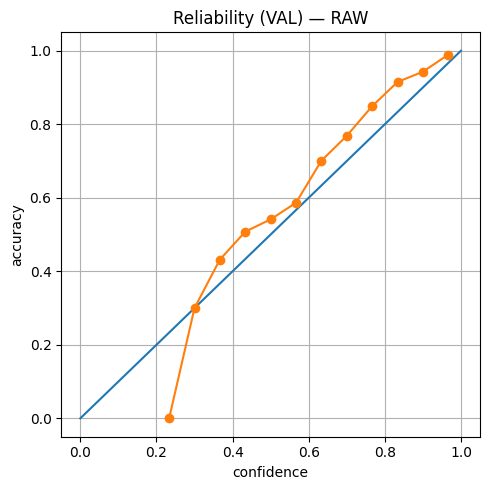

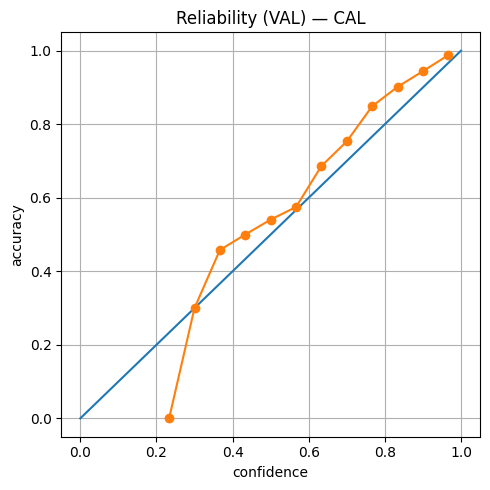

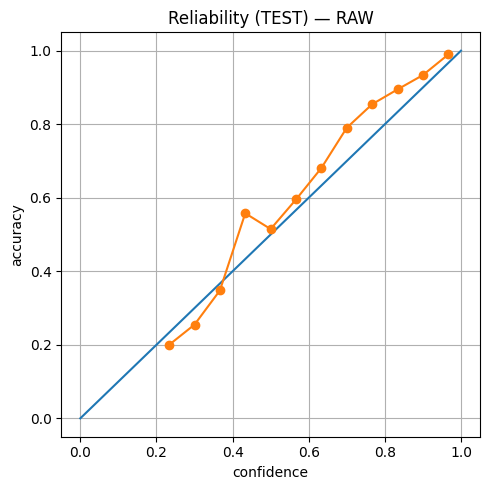

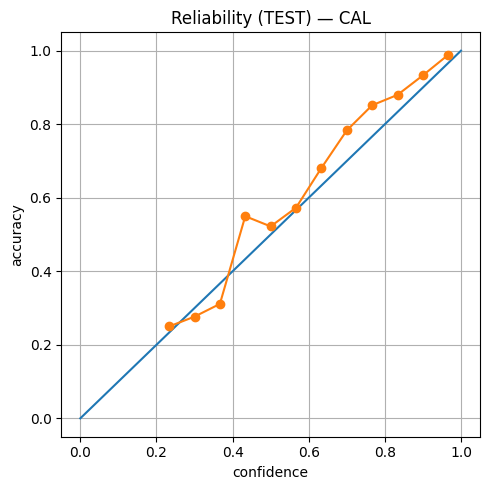

In [18]:
val_logits, val_y_np, _ = collect_logits_emb(model, val_loader)
test_logits, test_y_np, test_emb = collect_logits_emb(model, test_loader)

# ---- fit temperature scaler on VAL ----
temp = TemperatureScaler()
T = temp.fit(val_logits, val_y_np)

# ---- compute probs ----
val_probs_raw = softmax_np(val_logits)
test_probs_raw = softmax_np(test_logits)

val_logits_cal = temp(torch.tensor(val_logits, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()
test_logits_cal = temp(torch.tensor(test_logits, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()

val_probs_cal = softmax_np(val_logits_cal)
test_probs_cal = softmax_np(test_logits_cal)

# ---- calibration metrics ----
n_classes = int(val_probs_raw.shape[1])
calib_metrics = {
    "T": float(T),
    "val": {
        "ece_raw": ece_score(val_probs_raw, val_y_np),
        "ece_cal": ece_score(val_probs_cal, val_y_np),
        "nll_raw": nll_score(val_probs_raw, val_y_np),
        "nll_cal": nll_score(val_probs_cal, val_y_np),
        "brier_raw": brier_score(val_probs_raw, val_y_np, n_classes),
        "brier_cal": brier_score(val_probs_cal, val_y_np, n_classes),
    },
    "test": {
        "ece_raw": ece_score(test_probs_raw, test_y_np),
        "ece_cal": ece_score(test_probs_cal, test_y_np),
        "nll_raw": nll_score(test_probs_raw, test_y_np),
        "nll_cal": nll_score(test_probs_cal, test_y_np),
        "brier_raw": brier_score(test_probs_raw, test_y_np, n_classes),
        "brier_cal": brier_score(test_probs_cal, test_y_np, n_classes),
    },
}
save_json(paths["logs"] / "temperature_scaling_metrics.json", calib_metrics)
torch.save({"state_dict": temp.state_dict(), "T": float(T)}, paths["models"] / "temperature_scaler.pt")

print("Temperature T:", float(T))
print("VAL  | ECE:", calib_metrics["val"]["ece_raw"], "->", calib_metrics["val"]["ece_cal"],
      "| NLL:", calib_metrics["val"]["nll_raw"], "->", calib_metrics["val"]["nll_cal"],
      "| Brier:", calib_metrics["val"]["brier_raw"], "->", calib_metrics["val"]["brier_cal"])
print("TEST | ECE:", calib_metrics["test"]["ece_raw"], "->", calib_metrics["test"]["ece_cal"],
      "| NLL:", calib_metrics["test"]["nll_raw"], "->", calib_metrics["test"]["nll_cal"],
      "| Brier:", calib_metrics["test"]["brier_raw"], "->", calib_metrics["test"]["brier_cal"])

# ---- reliability plots (VAL + TEST, raw + cal) ----
plot_reliability(val_probs_raw, val_y_np, "Reliability (VAL) — RAW")
save_fig(paths["plots"] / "reliability_val_raw.png")
plt.show()

plot_reliability(val_probs_cal, val_y_np, "Reliability (VAL) — CAL")
save_fig(paths["plots"] / "reliability_val_cal.png")
plt.show()

plot_reliability(test_probs_raw, test_y_np, "Reliability (TEST) — RAW")
save_fig(paths["plots"] / "reliability_test_raw.png")
plt.show()

plot_reliability(test_probs_cal, test_y_np, "Reliability (TEST) — CAL")
save_fig(paths["plots"] / "reliability_test_cal.png")
plt.show()

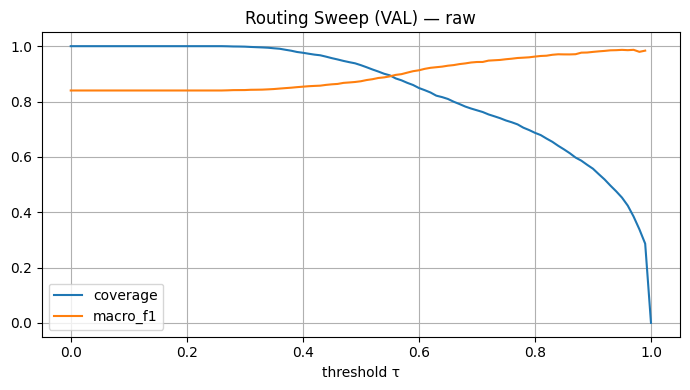

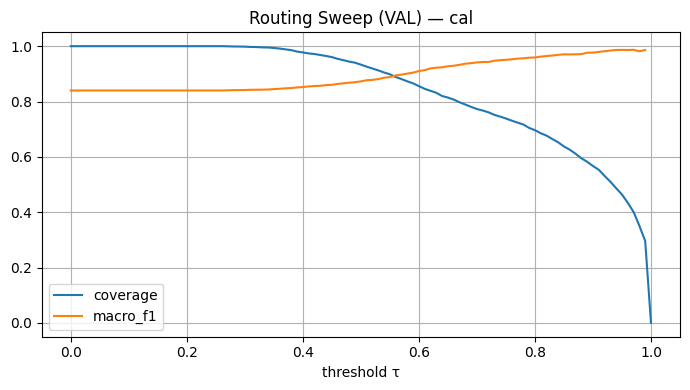

Routing selection: {'use_temperature_for_routing': True, 'selected': 'cal', 'criterion': 'val_utility_threshold_routing', 'raw_val_utility': 0.32802193063183094, 'cal_val_utility': 0.34575245463706267}


In [19]:
def compare_threshold_routing(val_probs: np.ndarray, test_probs: np.ndarray, tag: str) -> dict:
    grid_val = routing_sweep(val_probs, val_y_np)
    tau = pick_tau(grid_val)

    mean_conf = float(val_probs.max(axis=1).mean())
    beta = float(max(1.0, np.log(len(classes) + 1)))
    route_cost = float(max(0.01, min(0.25, 0.5 * (1.0 - mean_conf))))

    val_conf = val_probs.max(axis=1)
    val_pred = val_probs.argmax(axis=1)
    val_actions = np.where(val_conf >= tau, 0, 1)
    val_metrics = evaluate_policy(val_y_np, val_pred, val_actions, beta, route_cost)

    test_conf = test_probs.max(axis=1)
    test_pred = test_probs.argmax(axis=1)
    test_actions = np.where(test_conf >= tau, 0, 1)
    test_metrics = evaluate_policy(test_y_np, test_pred, test_actions, beta, route_cost)

    grid_val.to_csv(paths["logs"] / f"routing_sweep_val_{tag}.csv", index=False)

    plt.figure(figsize=(7, 4))
    plt.plot(grid_val["threshold"], grid_val["coverage"], label="coverage")
    plt.plot(grid_val["threshold"], grid_val["macro_f1"], label="macro_f1")
    plt.xlabel("threshold τ")
    plt.title(f"Routing Sweep (VAL) — {tag}")
    plt.legend()
    plt.grid(True)
    save_fig(paths["plots"] / f"routing_sweep_val_{tag}.png")
    plt.show()

    return {
        "tag": tag,
        "tau": float(tau),
        "beta": float(beta),
        "route_cost": float(route_cost),
        "val_metrics": val_metrics,
        "test_metrics": test_metrics,
    }


raw_routing = compare_threshold_routing(val_probs_raw, test_probs_raw, "raw")
cal_routing = compare_threshold_routing(val_probs_cal, test_probs_cal, "cal")

routing_compare = {"raw": raw_routing, "cal": cal_routing}
save_json(paths["logs"] / "routing_compare_threshold.json", routing_compare)

USE_TEMPERATURE_FOR_ROUTING = bool(cal_routing["val_metrics"]["utility"] > raw_routing["val_metrics"]["utility"])
choice = {
    "use_temperature_for_routing": USE_TEMPERATURE_FOR_ROUTING,
    "selected": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    "criterion": "val_utility_threshold_routing",
    "raw_val_utility": float(raw_routing["val_metrics"]["utility"]),
    "cal_val_utility": float(cal_routing["val_metrics"]["utility"]),
}
save_json(paths["logs"] / "routing_choice.json", choice)

print("Routing selection:", choice)

In [20]:
def probs_to_state(probs: np.ndarray) -> np.ndarray:
    probs = np.asarray(probs, dtype=np.float32)
    conf = probs.max(axis=1, keepdims=True)
    top2 = np.partition(probs, -2, axis=1)[:, -2:]
    margin = (top2[:, 1] - top2[:, 0]).reshape(-1, 1).astype(np.float32)
    entropy = (-np.sum(probs * np.log(np.clip(probs, 1e-9, 1.0)), axis=1, keepdims=True)).astype(np.float32)
    return np.concatenate([probs, conf.astype(np.float32), entropy, margin], axis=1).astype(np.float32)


@torch.no_grad()
def probs_from_logits_selected(logits_np: np.ndarray) -> np.ndarray:
    if USE_TEMPERATURE_FOR_ROUTING:
        logits_np = temp(torch.tensor(logits_np, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()
    return softmax_np(logits_np)


# Train logits from the original (pre-SMOTE) train split
train_raw_loader = DataLoader(Tabular1DDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
train_logits, train_y_np, _ = collect_logits_emb(model, train_raw_loader)

# Selected probs
train_probs_sel = probs_from_logits_selected(train_logits)
val_probs_sel = probs_from_logits_selected(val_logits)
test_probs_sel = probs_from_logits_selected(test_logits)

train_state = probs_to_state(train_probs_sel)
val_state = probs_to_state(val_probs_sel)
test_state = probs_to_state(test_probs_sel)

train_pred = train_probs_sel.argmax(axis=1)
val_pred = val_probs_sel.argmax(axis=1)
test_pred = test_probs_sel.argmax(axis=1)

print("RL state dim:", int(train_state.shape[1]))

np.savez_compressed(
    paths["cache"] / "routing_selected_arrays.npz",
    use_temperature_for_routing=np.array([int(USE_TEMPERATURE_FOR_ROUTING)]),
    train_logits=train_logits, val_logits=val_logits, test_logits=test_logits,
    train_probs=train_probs_sel, val_probs=val_probs_sel, test_probs=test_probs_sel,
    train_y=train_y_np, val_y=val_y_np, test_y=test_y_np,
    test_emb=test_emb,
)


RL state dim: 10


In [21]:
def set_seed(seed: int) -> None:
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class RLDecisionLayer(nn.Module):
    def __init__(self, in_dim: int, hidden: int = 64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def forward(self, s: torch.Tensor) -> torch.Tensor:
        return self.net(s)


class ReplayBuffer:
    def __init__(self, capacity: int, state_dim: int):
        self.capacity = int(capacity)
        self.state = np.zeros((capacity, state_dim), dtype=np.float32)
        self.action = np.zeros((capacity,), dtype=np.int64)
        self.reward = np.zeros((capacity,), dtype=np.float32)
        self.ptr = 0
        self.size = 0

    def add(self, s: np.ndarray, a: int, r: float) -> None:
        i = self.ptr
        self.state[i] = s
        self.action[i] = int(a)
        self.reward[i] = float(r)
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int):
        idx = np.random.randint(0, self.size, size=batch_size)
        return self.state[idx], self.action[idx], self.reward[idx]


def compute_reward(action: int, is_correct: bool, beta: float, route_cost: float) -> float:
    if action == 0:
        return 1.0 if is_correct else -float(beta)
    return -float(route_cost)


@torch.no_grad()
def policy_actions(policy: nn.Module, states: np.ndarray, batch: int = 4096) -> np.ndarray:
    policy.eval()
    out = []
    for i in range(0, len(states), batch):
        s = torch.tensor(states[i:i + batch], dtype=torch.float32, device=DEVICE)
        q = policy(s)
        out.append(q.argmax(dim=1).detach().cpu().numpy())
    return np.concatenate(out, axis=0) if out else np.array([], dtype=int)


In [22]:
def train_dqn_bandit(
        train_states: np.ndarray,
        train_y: np.ndarray,
        train_pred: np.ndarray,
        val_states: np.ndarray,
        val_y: np.ndarray,
        val_pred: np.ndarray,
        beta: float,
        route_cost: float,
        seed: int,
        hidden: int = 64,
        steps: int = 9000,
        batch_size: int = 512,
        buffer_size: int = 50000,
        warmup: int = 1500,
        lr: float = 1e-3,
        eps_start: float = 1.0,
        eps_end: float = 0.05,
        eps_decay: float = 0.9995,
):
    set_seed(seed)
    state_dim = train_states.shape[1]
    policy = RLDecisionLayer(state_dim, hidden=hidden).to(DEVICE)
    opt = torch.optim.AdamW(policy.parameters(), lr=lr, weight_decay=1e-4)
    buf = ReplayBuffer(buffer_size, state_dim)

    eps = eps_start
    best_val_util = -1e18
    best_state = None

    n = len(train_states)
    for t in range(1, steps + 1):
        i = np.random.randint(0, n)
        s = train_states[i]
        correct = bool(train_pred[i] == train_y[i])

        if np.random.rand() < eps:
            a = np.random.randint(0, 2)
        else:
            with torch.no_grad():
                q = policy(torch.tensor(s, dtype=torch.float32, device=DEVICE).unsqueeze(0))
                a = int(q.argmax(dim=1).item())

        r = compute_reward(a, correct, beta, route_cost)
        buf.add(s, a, r)
        eps = max(eps_end, eps * eps_decay)

        if buf.size >= warmup:
            s_b, a_b, r_b = buf.sample(batch_size)
            s_t = torch.tensor(s_b, dtype=torch.float32, device=DEVICE)
            a_t = torch.tensor(a_b, dtype=torch.int64, device=DEVICE).unsqueeze(1)
            r_t = torch.tensor(r_b, dtype=torch.float32, device=DEVICE).unsqueeze(1)

            q = policy(s_t).gather(1, a_t)
            loss = F.smooth_l1_loss(q, r_t)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 2.0)
            opt.step()

        if t % 1500 == 0:
            act_val = policy_actions(policy, val_states)
            val_m = evaluate_policy(val_y, val_pred, act_val, beta, route_cost)
            if val_m["utility"] > best_val_util:
                best_val_util = val_m["utility"]
                best_state = {k: v.detach().cpu().clone() for k, v in policy.state_dict().items()}
            print(
                f"step={t} eps={eps:.3f} val_utility={val_m['utility']:.4f} coverage={val_m['coverage']:.3f} macro_f1={val_m['macro_f1_accept']:.4f}"
            )

    if best_state is not None:
        policy.load_state_dict(best_state)
    return policy


# same heuristic grids you already use
mean_conf = float(val_probs_sel.max(axis=1).mean())
base_beta = float(max(1.0, np.log(len(classes) + 1)))
beta_grid = [base_beta * k for k in [1.0, 2.0, 3.0, 4.0]]

c_base = float(max(0.01, min(0.25, 0.5 * (1.0 - mean_conf))))
route_cost_grid = [c_base * k for k in [0.5, 1.0, 2.0, 4.0]]

best = None
best_policy = None

for beta in beta_grid:
    for c in route_cost_grid:
        pol = train_dqn_bandit(
            train_state, train_y_np, train_pred,
            val_state, val_y_np, val_pred,
            beta=float(beta),
            route_cost=float(c),
            seed=SEED
        )
        val_actions = policy_actions(pol, val_state)
        val_metrics = evaluate_policy(val_y_np, val_pred, val_actions, float(beta), float(c))
        cand = {"beta": float(beta), "route_cost": float(c), "val": val_metrics}
        if (best is None) or (cand["val"]["utility"] > best["val"]["utility"]):
            best = cand
            best_policy = pol

print("Selected RL params:", best)

test_actions = policy_actions(best_policy, test_state)
test_metrics_rl = evaluate_policy(test_y_np, test_pred, test_actions, best["beta"], best["route_cost"])
print("Test RL metrics:", test_metrics_rl)

save_json(paths["logs"] / "rl_selected.json", best)
save_json(paths["logs"] / "rl_test_metrics.json", test_metrics_rl)

torch.save(
    {
        "state_dict": best_policy.state_dict(),
        "state_dim": int(train_state.shape[1]),
        "hidden": 64,
        "beta": float(best["beta"]),
        "route_cost": float(best["route_cost"]),
        "use_temperature_for_routing": bool(USE_TEMPERATURE_FOR_ROUTING),
        "selected_probs_variant": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    },
    paths["models"] / "rl_policy.pt"
)

np.save(paths["cache"] / "test_actions_rl.npy", test_actions)

step=1500 eps=0.472 val_utility=-0.0390 coverage=0.000 macro_f1=0.0000
step=3000 eps=0.223 val_utility=0.6682 coverage=0.908 macro_f1=0.8949
step=4500 eps=0.105 val_utility=0.6779 coverage=0.887 macro_f1=0.9059
step=6000 eps=0.050 val_utility=0.6851 coverage=0.891 macro_f1=0.9085
step=7500 eps=0.050 val_utility=0.6876 coverage=0.892 macro_f1=0.9108
step=9000 eps=0.050 val_utility=0.6973 coverage=0.888 macro_f1=0.9173
step=1500 eps=0.472 val_utility=-0.0785 coverage=0.002 macro_f1=0.1786
step=3000 eps=0.223 val_utility=0.6686 coverage=0.911 macro_f1=0.8976
step=4500 eps=0.105 val_utility=0.6744 coverage=0.893 macro_f1=0.9050
step=6000 eps=0.050 val_utility=0.6824 coverage=0.890 macro_f1=0.9095
step=7500 eps=0.050 val_utility=0.6858 coverage=0.899 macro_f1=0.9087
step=9000 eps=0.050 val_utility=0.6897 coverage=0.889 macro_f1=0.9146
step=1500 eps=0.472 val_utility=-0.1551 coverage=0.002 macro_f1=0.1693
step=3000 eps=0.223 val_utility=0.6579 coverage=0.922 macro_f1=0.8888
step=4500 eps=0.1

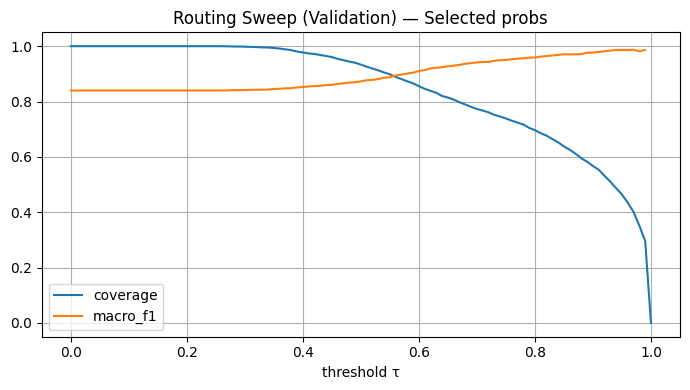

Chosen τ: 0.97
Threshold test metrics: {'coverage': 0.41136978884677855, 'macro_f1_accept': 0.9911030780302991, 'acc_accept': 0.9949986838641748, 'routed': 5436, 'accepted': 3799, 'utility': 0.38256932973875524, 'wrong_accept': 19, 'correct_accept': 3780}


In [23]:
grid = routing_sweep(val_probs_sel, val_y_np)
grid.to_csv(paths["logs"] / "routing_sweep_val_selected.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(grid["threshold"], grid["coverage"], label="coverage")
plt.plot(grid["threshold"], grid["macro_f1"], label="macro_f1")
plt.xlabel("threshold τ")
plt.title("Routing Sweep (Validation) — Selected probs")
plt.legend()
plt.grid(True)
save_fig(paths["plots"] / "routing_sweep_val_selected.png")
plt.show()

eligible = grid.dropna().sort_values(["macro_f1", "coverage"], ascending=[False, False])
tau = float(eligible.iloc[0]["threshold"]) if len(eligible) else 0.0
print("Chosen τ:", tau)

conf_test = test_probs_sel.max(axis=1)
actions_thr = np.where(conf_test >= tau, 0, 1)

thr_metrics = evaluate_policy(test_y_np, test_pred, actions_thr, float(best["beta"]), float(best["route_cost"]))
print("Threshold test metrics:", thr_metrics)

save_json(paths["logs"] / "routing_tau.json", {"tau": float(tau)})
save_json(paths["logs"] / "threshold_test_metrics.json", thr_metrics)
np.save(paths["cache"] / "test_actions_threshold.npy", actions_thr)


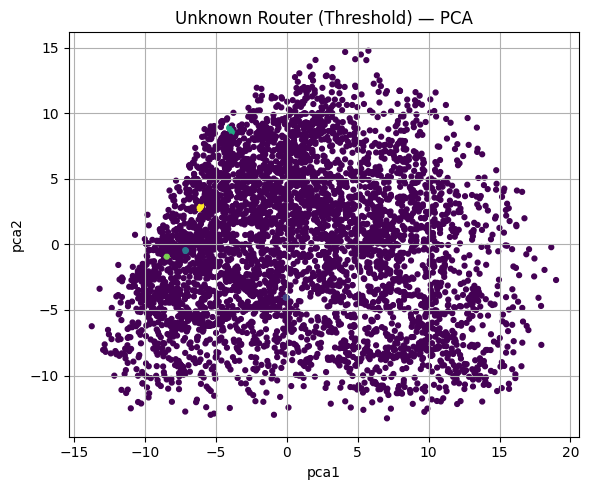

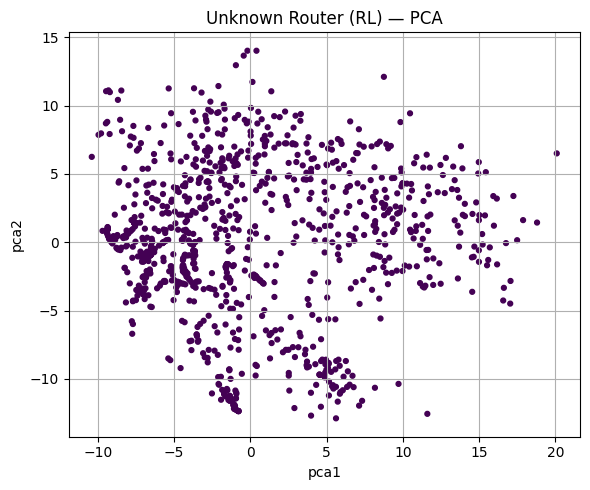

Unknown(threshold): {'tau': 0.97, 'routed_count': 5436, 'dbscan_eps': 0.7, 'dbscan_min_samples': 20, 'clusters': [{'cluster_id': -1, 'count': 5266}, {'cluster_id': 0, 'count': 40}, {'cluster_id': 1, 'count': 34}, {'cluster_id': 2, 'count': 32}, {'cluster_id': 3, 'count': 34}, {'cluster_id': 4, 'count': 30}]}
Unknown(RL): {'beta': 2.0794415416798357, 'route_cost': 0.038164615631103516, 'routed_count': 1024, 'dbscan_eps': 0.7, 'dbscan_min_samples': 20, 'clusters': [{'cluster_id': -1, 'count': 1024}]}


In [24]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


def cluster_unknowns(embeddings: np.ndarray, eps: float, min_samples: int) -> np.ndarray:
    if embeddings is None or len(embeddings) == 0:
        return np.array([], dtype=int)
    Z = StandardScaler().fit_transform(embeddings)
    return DBSCAN(eps=float(eps), min_samples=int(min_samples), metric="euclidean").fit_predict(Z)


def pca_plot_save(embeddings: np.ndarray, labels: np.ndarray, title: str, save_path: Path) -> None:
    if embeddings is None or len(embeddings) == 0:
        print(f"{title}: no embeddings to plot.")
        return
    xy = PCA(n_components=2, random_state=SEED).fit_transform(embeddings)
    plt.figure(figsize=(6, 5))
    plt.scatter(xy[:, 0], xy[:, 1], c=labels, s=12)
    plt.xlabel("pca1")
    plt.ylabel("pca2")
    plt.title(title)
    plt.grid(True)
    save_fig(save_path)
    plt.show()


def _cluster_summary(labels: np.ndarray) -> list[dict]:
    if labels is None or labels.size == 0:
        return []
    vc = pd.Series(labels).value_counts(dropna=False).sort_index()
    return [{"cluster_id": int(i), "count": int(c)} for i, c in vc.items()]


# Threshold-routed unknowns
routed_thr = (actions_thr == 1)
emb_thr = test_emb[routed_thr]
labels_thr = cluster_unknowns(emb_thr, DBSCAN_EPS, DBSCAN_MIN_SAMPLES)
pca_plot_save(emb_thr, labels_thr, "Unknown Router (Threshold) — PCA",
              paths["plots"] / "unknown_router_threshold_pca.png")

unknown_thr = {
    "tau": float(tau),
    "routed_count": int(routed_thr.sum()),
    "dbscan_eps": float(DBSCAN_EPS),
    "dbscan_min_samples": int(DBSCAN_MIN_SAMPLES),
    "clusters": _cluster_summary(labels_thr)
}

# RL-routed unknowns
routed_rl = (test_actions == 1)
emb_rl = test_emb[routed_rl]
labels_rl = cluster_unknowns(emb_rl, DBSCAN_EPS, DBSCAN_MIN_SAMPLES)
pca_plot_save(emb_rl, labels_rl, "Unknown Router (RL) — PCA", paths["plots"] / "unknown_router_rl_pca.png")

unknown_rl = {
    "beta": float(best["beta"]),
    "route_cost": float(best["route_cost"]),
    "routed_count": int(routed_rl.sum()),
    "dbscan_eps": float(DBSCAN_EPS),
    "dbscan_min_samples": int(DBSCAN_MIN_SAMPLES),
    "clusters": _cluster_summary(labels_rl)
}

save_json(paths["logs"] / "unknown_router_threshold.json", unknown_thr)
save_json(paths["logs"] / "unknown_router_rl.json", unknown_rl)

print("Unknown(threshold):", unknown_thr)
print("Unknown(RL):", unknown_rl)

In [25]:
joblib.dump(le, paths["preprocess"] / "label_encoder.joblib")

run_card = {
    "run_name": str(RUN_NAME),
    "dataset_name": str(DATASET_NAME),
    "created_at": datetime.utcnow().isoformat() + "Z",
    "device": str(DEVICE),
    "n_classes": int(len(classes)),
    "final_feature_count": int(len(kept_features)),
    "temperature_T": float(T),
    "use_temperature_for_routing": bool(USE_TEMPERATURE_FOR_ROUTING),
    "selected_probs_variant": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    "tau_selected_probs": float(tau),
}
save_json(paths["logs"] / "run_card.json", run_card)

bundle_dir = paths["root"] / "bundle"
bundle_dir.mkdir(parents=True, exist_ok=True)

# Copy core artifacts (top-level convenience)
copy_items = [
    paths["models"] / "cnn_best.pt",
    paths["models"] / "temperature_scaler.pt",
    paths["models"] / "rl_policy.pt",
    paths["logs"] / "config.json",
    paths["logs"] / "classes.json",
    paths["logs"] / "kept_features.json",
    paths["logs"] / "run_card.json",
    paths["logs"] / "routing_choice.json",
    paths["logs"] / "temperature_scaling_metrics.json",
    paths["logs"] / "routing_compare_threshold.json",
    paths["logs"] / "rl_selected.json",
    paths["logs"] / "rl_test_metrics.json",
    paths["logs"] / "routing_tau.json",
    paths["logs"] / "threshold_test_metrics.json",
    paths["logs"] / "unknown_router_threshold.json",
    paths["logs"] / "unknown_router_rl.json",
    paths["cache"] / "test_actions_rl.npy",
    paths["cache"] / "test_actions_threshold.npy",
    paths["cache"] / "routing_selected_arrays.npz",
]

for fp in copy_items:
    if fp is not None and Path(fp).exists():
        shutil.copy2(fp, bundle_dir / Path(fp).name)

# Copy folders for full reproducibility
for folder_key in ["preprocess", "plots", "logs", "models", "cache"]:
    src = paths[folder_key]
    dst = bundle_dir / folder_key
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

inference_bundle = {
    "bundle_root": str(bundle_dir),
    "model_file": "cnn_best.pt",
    "temperature_scaler_file": "temperature_scaler.pt",
    "rl_policy_file": "rl_policy.pt",
    "use_temperature_for_routing": bool(USE_TEMPERATURE_FOR_ROUTING),
    "selected_probs_variant": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    "preprocess_dir": "preprocess",
    "logs_dir": "logs",
    "plots_dir": "plots",
    "models_dir": "models",
    "cache_dir": "cache",
}
save_json(bundle_dir / "inference_bundle.json", inference_bundle)

zip_path = shutil.make_archive(str(bundle_dir), "zip", root_dir=bundle_dir)
print("Bundle created:", zip_path)
print("Everything saved under:", paths["root"])

C:\Users\user\AppData\Local\Temp\ipykernel_23472\777525724.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at": datetime.utcnow().isoformat() + "Z",


Bundle created: D:\FYP_ML\FYP_V2\ISCX-stat\v5\v1\bundle.zip
Everything saved under: v5\v1
